# Task 2.1

We first plot $\text{Re}\langle a\rangle(t)$ for $\alpha = 1.0$

The jump operators we used were $\sqrt{\kappa_b}b$ and $\sqrt{\kappa_a}a$. Although 1.0(c) also used the jump operator $\sqrt{\kappa_2}(a^2 - \alpha^2)$, we do not use this to replace $\sqrt{\kappa_b}b$. This is because the parameters provided do not satisfy the requirement $\kappa_b \gg g_2, \epsilon_d$ to approximate the $b$ jump operator with this effective single-mode picture.

In [ ]:
import dynamiqs as dq
import jax.numpy as jnp
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit
import numpy as np

# Use double precision for slow decays in the Standard Track
dq.set_precision('single')

# Suggested starting truncations (need to be checked as alpha grows)
Na, Nb = 24, 6
a, b = dq.destroy(Na, Nb)

# System parameters converted to angular frequencies (rad/us)
g2 = 2 * jnp.pi * 0.763       
kappa_b = 2 * jnp.pi * 2.6         
kappa_a = 2 * jnp.pi * 9.3e-3      
alpha = 1.0
eps_d = alpha**2 * g2

# Two-photon Hamiltonian
H = g2 * (a @ a @ b.dag()) + g2 * (a.dag() @ a.dag() @ b) - eps_d * (b + b.dag())

# Jump operators for buffer loss and memory loss
jump_ops = [jnp.sqrt(kappa_b) * b, jnp.sqrt(kappa_a) * a]

# Initial state: Memory in |alpha>, Buffer in vacuum
psi0 = dq.tensor(dq.coherent(Na, alpha), dq.fock(Nb, 0))

# Time array in microseconds
tsave = jnp.linspace(0.0, 1500.0, 1500)

# Evolve the density matrix and track operators
# We track 'a' to extract Re<a>(t) for the bit-flip rate decay
exp_ops = [a, a.dag() @ a, b.dag() @ b]

# Create the ODE solver object with the increased step limit
# Loosen tolerances to handle the stiff ODE and massively increase the step ceiling
method = dq.method.Dopri5(max_steps=5_000_000, rtol=1e-5, atol=1e-7)

res = dq.mesolve(H, jump_ops, psi0, tsave, exp_ops=exp_ops, method=method)

In [ ]:
plt.plot(tsave, np.real(res.expects[0]))
plt.xlabel("t")
plt.ylabel(fr"$Re\langle a\rangle(t)$")

def bit_flip_decay(t, amplitude, gamma_x):
    return amplitude * np.exp(-gamma_x * t)

# Extract real part of <a> from your dynamiqs results
re_a = np.real(res.expects[0])

# 1. Slice out the initial inflation transient (e.g., first 2 us)
start_idx = np.searchsorted(tsave, 2.0)
t_fit = tsave[start_idx:]
re_a_fit = re_a[start_idx:]

# Shift time axis for numerical stability in the fit
t_shifted = t_fit - t_fit[0]

# 2. Fit the curve
initial_guess = [re_a_fit[0], 1e-4]
popt, pcov = curve_fit(bit_flip_decay, t_shifted, re_a_fit, p0=initial_guess)

amplitude_fit, gamma_x = popt
t_x = 1.0 / gamma_x

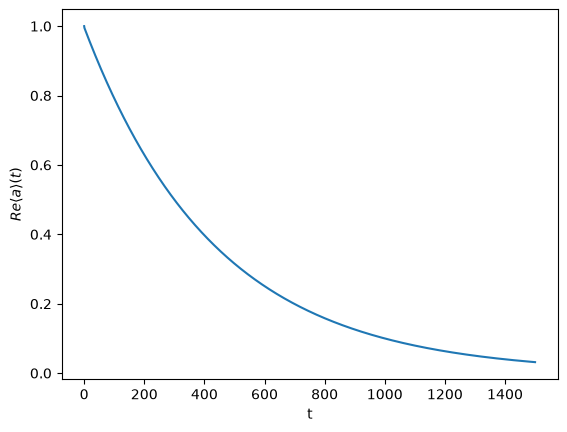

From this plot, by fitting an exponential $e^{-\Gamma_X t}$, we extra $\Gamma_X$.

We get a value $\Gamma_X = 0.00230066$.

Below we extend this process to different $\alpha$ values and compute $\Gamma_X(\alpha)$ for each. We then plot these $\Gamma_X(\alpha)$ against $\alpha^2$ and perform another exponential fit to estimate $\gamma$ in $\gamma \propto e^{-\gamma\alpha^2}$.

In [ ]:
# 1. System Parameters and Solver Setup
dq.set_precision('double')
Na, Nb = 24, 6
a, b = dq.destroy(Na, Nb)

g2 = 2 * jnp.pi * 0.763       
kappa_b = 2 * jnp.pi * 2.6         
kappa_a = 2 * jnp.pi * 9.3e-3      
jump_ops = [jnp.sqrt(kappa_b) * b, jnp.sqrt(kappa_a) * a]
exp_ops = [a, a.dag() @ a, b.dag() @ b]

# Loosened tolerances for stiff Lindbladian dynamics
method = dq.method.Dopri5(max_steps=10_000_000, rtol=1e-5, atol=1e-7)

def bit_flip_decay(t, amplitude, gamma_x):
    return amplitude * np.exp(-gamma_x * t)

# 2. Define the Sweep Setup
# Mapping alpha to a sufficient t_max (us) to capture the decay
alpha_sweep = {
    0.8: 200.0,
    0.9: 400.0,
    1.1: 4000.0,
}

results_alpha_sq = []
results_gamma_x = []

plt.figure(figsize=(14, 5))

# --- Subplot 1: The Decay Curves ---
ax1 = plt.subplot(1, 2, 1)

for alpha, t_max in alpha_sweep.items():
    
    print(f"Simulating alpha = {alpha} (t_max = {t_max} us)...")
    
    eps_d = (alpha**2) * g2
    H = g2 * (a @ a @ b.dag()) + g2 * (a.dag() @ a.dag() @ b) - eps_d * (b + b.dag())
    psi0 = dq.tensor(dq.coherent(Na, alpha), dq.fock(Nb, 0))
    
    # Keep array length fixed at 1500 to avoid XLA recompilation overhead
    tsave = jnp.linspace(0.0, t_max, 1500)
    
    res = dq.mesolve(H, jump_ops, psi0, tsave, exp_ops=exp_ops, method=method)
    re_a = np.real(res.expects[0])
    
    # Slice out first 2 us to remove the inflation transient
    start_idx = np.searchsorted(tsave, 2.0)
    t_fit = tsave[start_idx:]
    re_a_fit = re_a[start_idx:]
    t_shifted = t_fit - t_fit[0]
    
    # Fit exponential
    popt, _ = curve_fit(bit_flip_decay, t_shifted, re_a_fit, p0=[re_a_fit[0], 1e-4])
    gamma_x = popt[1]
    
    results_alpha_sq.append(alpha**2)
    results_gamma_x.append(gamma_x)
    
    # Plot normalized decay for visual comparison
    ax1.plot(t_shifted, re_a_fit / re_a_fit[0], label=rf'$\alpha={alpha}$')

ax1.set_xlabel("Time shifted ($\mu$s)")
ax1.set_ylabel(r"Normalized Re$\langle a \rangle(t)$")
ax1.set_title("Bit-Flip Decay Envelopes")
ax1.legend()

# --- Subplot 2: Log-Linear Extraction of Gamma ---
ax2 = plt.subplot(1, 2, 2)
alpha_sq_arr = np.array(results_alpha_sq)
gamma_x_arr = np.array(results_gamma_x)

# Perform linear fit: ln(Gamma_X) = -gamma * alpha^2 + C
log_gamma = np.log(gamma_x_arr)
slope, intercept = np.polyfit(alpha_sq_arr, log_gamma, 1)
gamma_extracted = -slope

ax2.scatter(alpha_sq_arr, log_gamma, color='black', zorder=5, label='Simulation data')

# Plot the fit line
fit_line = slope * alpha_sq_arr + intercept
ax2.plot(alpha_sq_arr, fit_line, color='red', linestyle='--', 
         label=rf'Fit: $\gamma = {gamma_extracted:.3f}$')

ax2.set_xlabel(r"$\alpha^2$ (Mean Photon Number)")
ax2.set_ylabel(r"$\ln(\Gamma_X)$")
ax2.set_title(r"Scaling of Bit-Flip Rate: $\Gamma_X \propto \exp(-\gamma \alpha^2)$")
ax2.legend()

plt.tight_layout()
plt.show()

print(f"\nExtraction Complete.")
print(f"Fitted gamma (γ) = {gamma_extracted:.4f}")

## Task 2.2

Depending on choice of basis, we encounter different errors.

In 2.1, we saw that the coherent basis is prone to bit-flip error. In particular, we saw how initializing in the $|\alpha\rangle$ state after

Now in 2.2, we saw that initializing in the parity basis state $|\alpha\rangle$, this state after time-evolution is prone to bit-flip error.